# Paper plots

End-to-end figures for both examples in *Learning Omega-Limit Partitions from Approximate Koopman
Invariants*, produced by calling the pipeline scripts' functions directly (no pipeline outputs are
written to `data/`). Per system:

1. **Partition** — Algorithm 1 with the parameters in `configs/<system>/build_partition.json`
   (`build_partition.build_partition_from_config`).
2. **Validation phase portrait** — labeled validation snapshots classified through anchors: correct,
   misclassified and dropped (robustness margin) points (`validate_partition` config).
3. **Regional EDMD vs vanilla EDMD** — models fitted with the dictionary that won the sweeps in
   the walkthrough notebooks (`BEST_EDMD`, overriding `build_multiple_linear_models.json`); lift-once
   rollouts from two initial conditions, one per attractor, as time series and in the phase plane.
4. **Rollout error curves** — `run_gated_evaluation = True`: relative and absolute error vs time on
   validation trajectories with correctly classified initial conditions, regional vs vanilla.

Every array a figure needs is cached in `data/paper_plots/<system>/*.npz`; the scripts in
`plotting/` rebuild the same figures from those files, so figure styling can be iterated
without re-running this notebook. Set `SAVE_DIR` to also write every figure as a PNG here. Run from `notebooks/` in the `macbook_env`
environment; the Duffing gated evaluation (400k validation snapshots) takes a couple of minutes.


In [1]:
import sys
from pathlib import Path

import numpy as np

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "opal").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path[:0] = [str(PROJECT_ROOT), str(PROJECT_ROOT / "scripts")]

import build_partition
import validate_partition
import build_multiple_linear_models as bmlm
from opal.anchors import classify_with_anchors, print_classification_table
from opal.paths import resolve
from opal.plotting import plot_misclassified_points, plot_rollout_phase_portrait, plot_state_partition_2d

SAVE_DIR = None   # e.g. PROJECT_ROOT / "figures/paper_plots"; None = show only

def cfg_path(system, stage):
    return PROJECT_ROOT / f"configs/{system}/{stage}.json"

def fig(system, name):
    return None if SAVE_DIR is None else Path(SAVE_DIR) / system / f"{name}.png"

DATA_DIR = PROJECT_ROOT / "data/paper_plots"   # cached arrays, consumed by plotting/*.py

def data_path(system, name):
    path = DATA_DIR / system / f"{name}.npz"
    path.parent.mkdir(parents=True, exist_ok=True)
    return path


## Duffing oscillator

In [2]:
SYSTEM, NAME = "duffing", "duffing_eqn"
BEST_EDMD = dict(edmd_gamma=1.0, edmd_d_poly=6, number_centers_edmd=100)   # best of the sweep in duffing_walkthrough.ipynb
ICS = [[-1.5, 0.3], [1.3, 0.4]]   # one initial condition per basin, as in the paper figure

### Partition (Algorithm 1) and validation phase portrait

 Data loaded from  data/duffing/duffing_data.npz
 Total data points:  50000
 RBF centers loaded from file: (500, 2)
Number of Dictionary elements = 501


Selected invariant modes: 2
Selected generalized eigenvalues:
[-5.49834349e-17  7.39220427e-05]


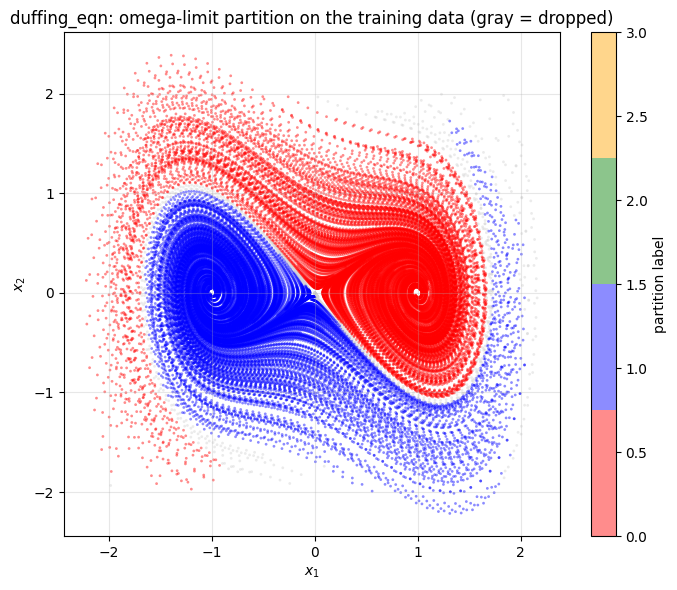

In [3]:
part_cfg = build_partition.load_settings(cfg_path(SYSTEM, "build_partition"))
part = build_partition.build_partition_from_config(part_cfg)
partition = part["inference"]
np.savez(data_path(SYSTEM, "partition"), X=part["X"], labels=part["result"]["final_labels_X"], system_name=NAME)
_ = plot_state_partition_2d(part["X"], part["result"]["final_labels_X"],
                            title=f"{NAME}: omega-limit partition on the training data (gray = dropped)",
                            save_path=fig(SYSTEM, "partition"))


+----------------------+---------------------+----------------------------+---------+--------+---------+
| Method               | Anchor mapping      | Metric                     | Correct | Total  | Rate    |
+======================+=====================+============================+=========+========+=========+
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (total data)      | 397498  | 399200 | 99.57%  |
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (un-dropped data) | 397498  | 397508 | 100.00% |
| GraphMergedPartition | anchor (0->1, 1->0) | dropped predictions        | 1692    | 399200 | 0.42%   |
+----------------------+---------------------+----------------------------+---------+--------+---------+


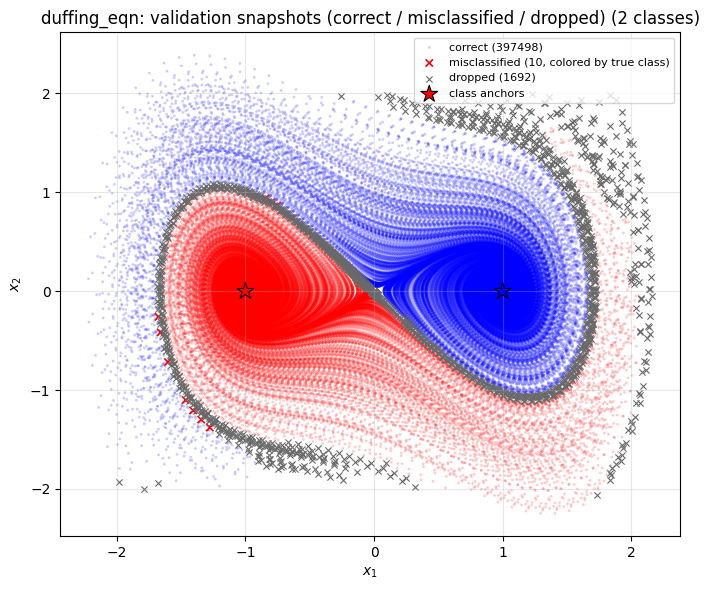

In [4]:
val_cfg = validate_partition.load_settings(cfg_path(SYSTEM, "validate_partition"))
X_val, labels_val = validate_partition.load_validation_data(resolve(val_cfg["validation_data_path"]))
res = classify_with_anchors(cfg=val_cfg, X=X_val, gt_labels=labels_val, partition=partition)
print_classification_table(res.table_rows)
np.savez(data_path(SYSTEM, "validation"), X=X_val, gt_labels=res.gt_labels, pred_labels=res.pred_mapped,
         anchors=res.anchors, system_name=NAME)
_ = plot_misclassified_points(X_val, res.gt_labels, res.pred_mapped, anchors=res.anchors,
                              title=f"{NAME}: validation snapshots (correct / misclassified / dropped)",
                              save_path=fig(SYSTEM, "validation_phase_portrait"))


### Regional EDMD vs vanilla EDMD: rollouts from two initial conditions

 Data loaded from data/duffing/duffing_validation_data.npz
 Total snapshot pairs: 399200
 RBF centers loaded from data/duffing/duffing_data.npz: (500, 2)


 Partition components present in data: [0, 1]
EDMD center selection: random subsample (100 of 500 pool centers)
EDMD centers shape: (100, 2)
 Switched EDMD dictionary: gamma = 1.0, d_poly = 6, 100 centers, 128 elements



Training diagnostics
  Total snapshot pairs: 399200
  Dropped (unclassified, label = -1): 1692 (0.42%)
  Fitted components: 2
    component 0: 201327 snapshot pairs
    component 1: 196181 snapshot pairs
  Switched EDMD fitted on 397508 of 399200 snapshot pairs (1692 excluded: partition-dropped or skipped components)

 Vanilla EDMD dictionary: same object as the switched EDMD dictionary


 Vanilla EDMD fitted on all 399200 of 399200 snapshot pairs (nothing dropped)

Phase plots: simulating 2 trajectory(s) from ICs_phase_plot


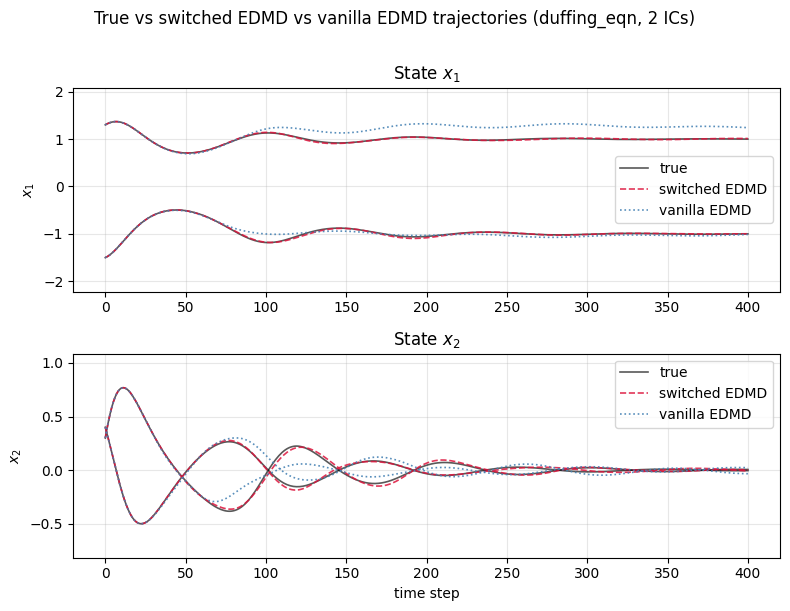

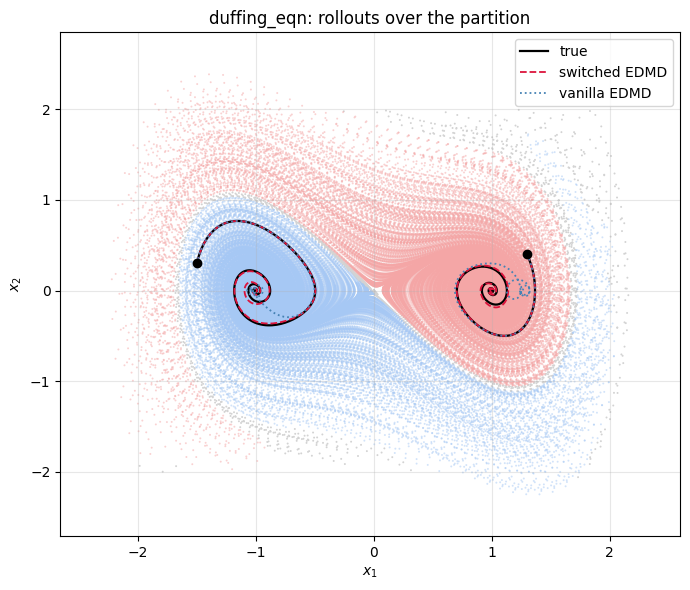

In [5]:
mlm_cfg = bmlm.load_settings(cfg_path(SYSTEM, "build_multiple_linear_models"))
mlm_cfg.update(BEST_EDMD, ICs_phase_plot=ICS, run_gated_evaluation=True)
X, Y, traj, centers_global, n = bmlm.load_fit_data(mlm_cfg)
fit = bmlm.fit_models_from_config(mlm_cfg, partition, X, Y, centers_global)

regional, vanilla = bmlm.phase_plot_rollouts(mlm_cfg, fit, partition, traj, n)
true_trajs, regional_trajs = bmlm._pack_rollouts(regional)
_, vanilla_trajs = bmlm._pack_rollouts(vanilla)
np.savez(data_path(SYSTEM, "rollouts"), true_trajs=true_trajs, regional_trajs=regional_trajs, vanilla_trajs=vanilla_trajs,
         X=X, labels=fit["labels"], system_name=NAME)
_ = bmlm.plot_phase_trajectories(regional, NAME, vanilla_rollouts=vanilla, show=True,
                                 save_path=fig(SYSTEM, "rollout_trajectories"))
_ = plot_rollout_phase_portrait(X, fit["labels"], regional, vanilla,
                                title=f"{NAME}: rollouts over the partition",
                                save_path=fig(SYSTEM, "rollout_phase_portrait"))


### Rollout error on validation trajectories (correctly classified initial conditions)


--- Classification-gated evaluation ---
Validation data: data/duffing/duffing_validation_data.npz
Samples: 399200
Fitted components: [0, 1]

--- Partition classification ---
Classes (anchors): 2
Anchor assignments:
  class 0: state=(-1, 0) -> partition 1
  class 1: state=(1, 0) -> partition 0
Predicted partition labels (excluding dropped): [0, 1]

+----------------------+---------------------+----------------------------+---------+--------+---------+
| Method               | Anchor mapping      | Metric                     | Correct | Total  | Rate    |
+======================+=====================+============================+=========+========+=========+
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (total data)      | 397498  | 399200 | 99.57%  |
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (un-dropped data) | 397498  | 397508 | 100.00% |
| GraphMergedPartition | anchor (0->1, 1->0) | dropped predictions        | 1692    | 399200 | 0.42%   |
+------------------

--- One-step EDMD, switched vs vanilla (correctly classified snapshots) ---
+-----------+---------+-----------------+------------------+-----------------+------------------+----------------+-----------------+
| Component | Samples | Lifted rel (sw) | Lifted rel (van) | State RMSE (sw) | State RMSE (van) | State rel (sw) | State rel (van) |
+===========+=========+=================+==================+=================+==================+================+=================+
| 0         | 201317  | 3.4420e-05      | 1.4060e-04       | 3.6575e-08      | 3.6641e-08       | 1.7780e-08     | 1.7779e-08      |
| 1         | 196181  | 8.5483e-06      | 1.5517e-04       | 3.5161e-08      | 3.5230e-08       | 1.7435e-08     | 1.7426e-08      |
| all       | 397498  | 2.1651e-05      | 1.4779e-04       | 3.5884e-08      | 3.5951e-08       | 1.7610e-08     | 1.7605e-08      |
+-----------+---------+-----------------+------------------+-----------------+------------------+----------------+------------


--- T-step rollout (correct IC only) ---
Horizon = 400, 50 trajectories sampled, reclassify_each_step = False
  Evaluated rollouts (correct IC): 47/50 (skipped 3 misclassified ICs; same set for both models)
+------------------------------+---------------+--------------+
| Metric                       | switched EDMD | vanilla EDMD |
+==============================+===============+==============+
| Valid rollouts               | 47            | 47           |
| Mean rollout RMSE            | 0.0466268     | 0.253375     |
| Max rollout RMSE             | 0.120905      | 1.10189      |
| Dropped rollout steps (frac) | 0.0000        | 0.0000       |
+------------------------------+---------------+--------------+

--- Rollout relative error at selected time steps (correct IC only) ---
+---------------------------------+---+-----------+----------+-----------+-----------+
| Time step                       | 0 | 50        | 100      | 200       | 300       |
+================================

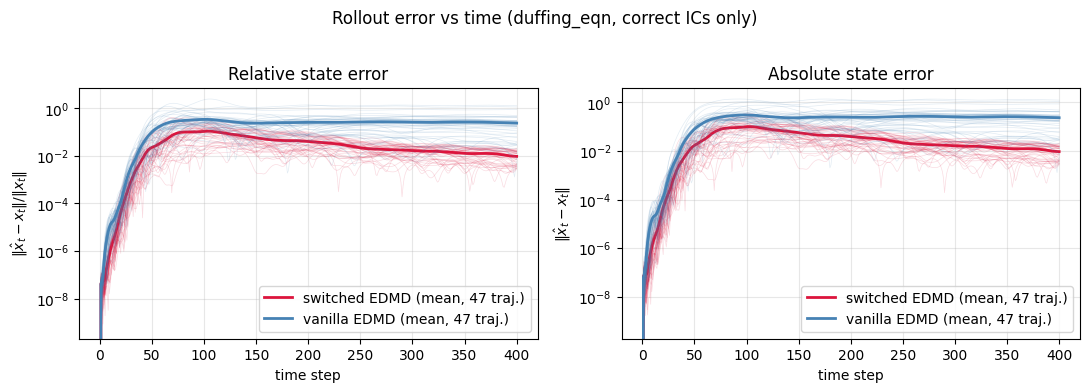

In [6]:
ev = bmlm.run_classification_gated_evaluation(mlm_cfg, models=fit["models"], partition=partition,
                                              Phi_edmd=fit["Phi_edmd"], vanilla_model=fit["vanilla_model"],
                                              Phi_vanilla=fit["Phi_vanilla"])
c = ev["error_curves"]
np.savez(data_path(SYSTEM, "rollout_errors"), **c, rel_rmse_times=ev["rel_rmse_times"], rel_rmse_values=ev["rel_rmse_values"],
         vanilla_rel_rmse_values=ev["vanilla_rel_rmse_values"], partition_accuracy=ev["partition_accuracy"], system_name=NAME)
_ = bmlm.plot_rollout_errors(c["rel_regional"], c["abs_regional"], rel_vanilla=c.get("rel_vanilla"),
                             abs_vanilla=c.get("abs_vanilla"), system_name=NAME, show=True,
                             save_path=fig(SYSTEM, "rollout_errors"))


## Bistable oscillations

In [7]:
SYSTEM, NAME = "bistable_oscillations", "bistable_oscillations"
BEST_EDMD = dict(edmd_gamma=1.0, edmd_d_poly=6, number_centers_edmd=100)   # best of the sweep in bistable_oscillations_walkthrough.ipynb
ICS = [[1.5 * np.cos(np.pi / 4), 1.5 * np.sin(np.pi / 4)], [2.5 * np.cos(-2 * np.pi / 3), 2.5 * np.sin(-2 * np.pi / 3)]]   # r0 = 1.5 -> inner cycle r = 1, r0 = 2.5 -> outer cycle r = 3

### Partition (Algorithm 1) and validation phase portrait

 Data loaded from  data/bistable_oscillations/bistable_oscillations_data.npz
 Total data points:  25000
 RBF centers loaded from file: (500, 2)
Number of Dictionary elements = 510


Selected invariant modes: 2
Selected generalized eigenvalues:
[-1.13177040e-13  3.41758047e-05]


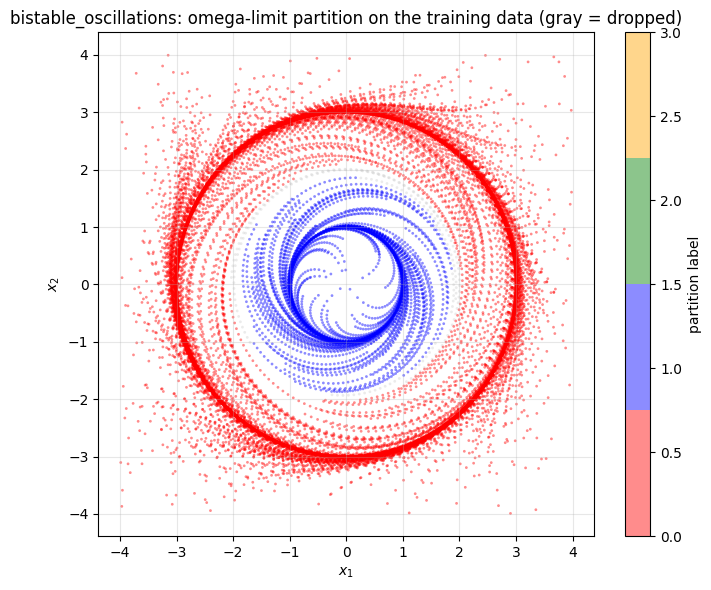

In [8]:
part_cfg = build_partition.load_settings(cfg_path(SYSTEM, "build_partition"))
part = build_partition.build_partition_from_config(part_cfg)
partition = part["inference"]
np.savez(data_path(SYSTEM, "partition"), X=part["X"], labels=part["result"]["final_labels_X"], system_name=NAME)
_ = plot_state_partition_2d(part["X"], part["result"]["final_labels_X"],
                            title=f"{NAME}: omega-limit partition on the training data (gray = dropped)",
                            save_path=fig(SYSTEM, "partition"))


+----------------------+---------------------+----------------------------+---------+--------+---------+
| Method               | Anchor mapping      | Metric                     | Correct | Total  | Rate    |
+======================+=====================+============================+=========+========+=========+
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (total data)      | 149653  | 150000 | 99.77%  |
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (un-dropped data) | 149653  | 149653 | 100.00% |
| GraphMergedPartition | anchor (0->1, 1->0) | dropped predictions        | 347     | 150000 | 0.23%   |
+----------------------+---------------------+----------------------------+---------+--------+---------+


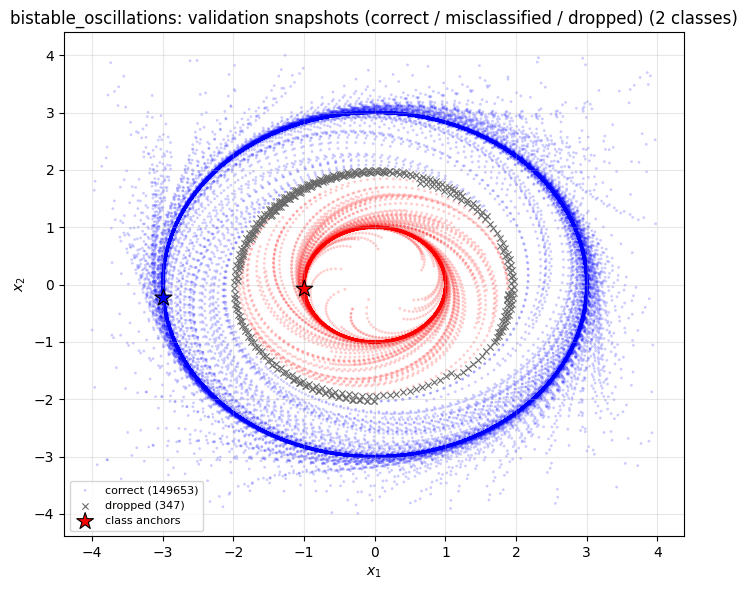

In [9]:
val_cfg = validate_partition.load_settings(cfg_path(SYSTEM, "validate_partition"))
X_val, labels_val = validate_partition.load_validation_data(resolve(val_cfg["validation_data_path"]))
res = classify_with_anchors(cfg=val_cfg, X=X_val, gt_labels=labels_val, partition=partition)
print_classification_table(res.table_rows)
np.savez(data_path(SYSTEM, "validation"), X=X_val, gt_labels=res.gt_labels, pred_labels=res.pred_mapped,
         anchors=res.anchors, system_name=NAME)
_ = plot_misclassified_points(X_val, res.gt_labels, res.pred_mapped, anchors=res.anchors,
                              title=f"{NAME}: validation snapshots (correct / misclassified / dropped)",
                              save_path=fig(SYSTEM, "validation_phase_portrait"))


### Regional EDMD vs vanilla EDMD: rollouts from two initial conditions

 Data loaded from data/bistable_oscillations/bistable_oscillations_validation_data.npz
 Total snapshot pairs: 150000
 RBF centers loaded from data/bistable_oscillations/bistable_oscillations_data.npz: (500, 2)


 Partition components present in data: [0, 1]
EDMD center selection: random subsample (100 of 500 pool centers)
EDMD centers shape: (100, 2)
 Switched EDMD dictionary: gamma = 1.0, d_poly = 6, 100 centers, 128 elements



Training diagnostics
  Total snapshot pairs: 150000
  Dropped (unclassified, label = -1): 347 (0.23%)
  Fitted components: 2
    component 0: 121757 snapshot pairs
    component 1: 27896 snapshot pairs
  Switched EDMD fitted on 149653 of 150000 snapshot pairs (347 excluded: partition-dropped or skipped components)

 Vanilla EDMD dictionary: same object as the switched EDMD dictionary


 Vanilla EDMD fitted on all 150000 of 150000 snapshot pairs (nothing dropped)

Phase plots: simulating 2 trajectory(s) from ICs_phase_plot


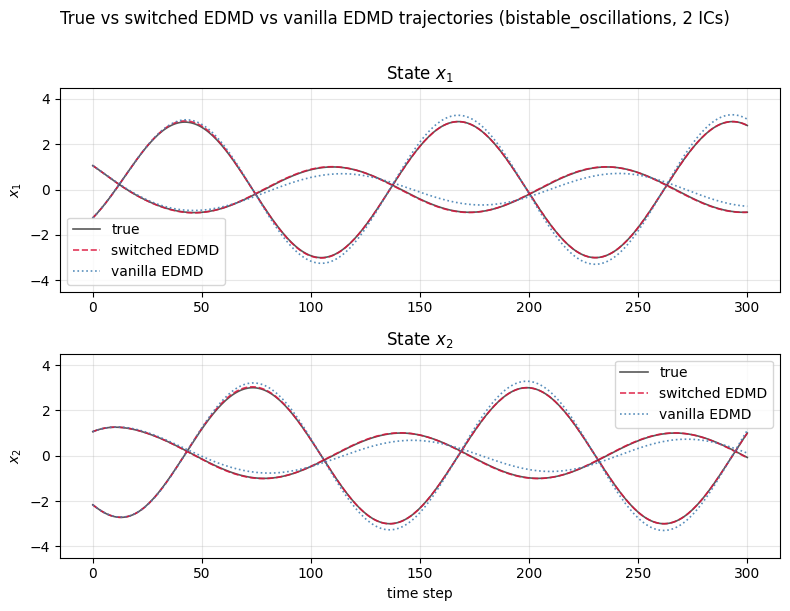

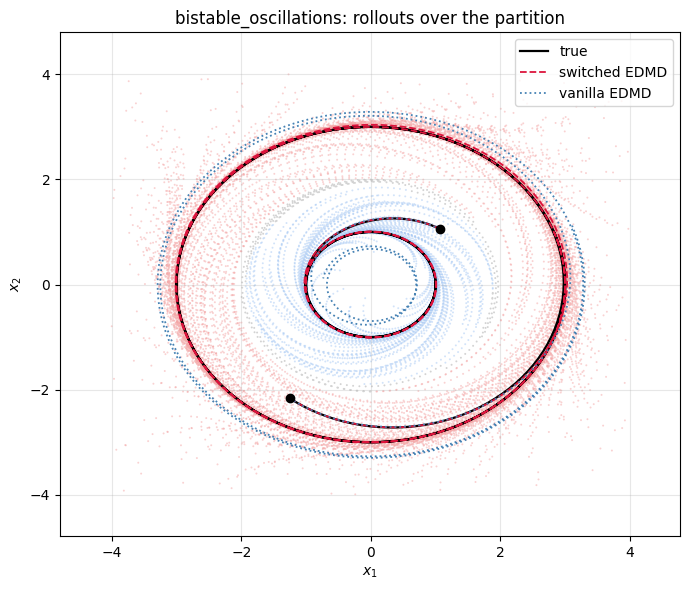

In [10]:
mlm_cfg = bmlm.load_settings(cfg_path(SYSTEM, "build_multiple_linear_models"))
mlm_cfg.update(BEST_EDMD, ICs_phase_plot=ICS, run_gated_evaluation=True)
X, Y, traj, centers_global, n = bmlm.load_fit_data(mlm_cfg)
fit = bmlm.fit_models_from_config(mlm_cfg, partition, X, Y, centers_global)

regional, vanilla = bmlm.phase_plot_rollouts(mlm_cfg, fit, partition, traj, n)
true_trajs, regional_trajs = bmlm._pack_rollouts(regional)
_, vanilla_trajs = bmlm._pack_rollouts(vanilla)
np.savez(data_path(SYSTEM, "rollouts"), true_trajs=true_trajs, regional_trajs=regional_trajs, vanilla_trajs=vanilla_trajs,
         X=X, labels=fit["labels"], system_name=NAME)
_ = bmlm.plot_phase_trajectories(regional, NAME, vanilla_rollouts=vanilla, show=True,
                                 save_path=fig(SYSTEM, "rollout_trajectories"))
_ = plot_rollout_phase_portrait(X, fit["labels"], regional, vanilla,
                                title=f"{NAME}: rollouts over the partition",
                                save_path=fig(SYSTEM, "rollout_phase_portrait"))


### Rollout error on validation trajectories (correctly classified initial conditions)


--- Classification-gated evaluation ---
Validation data: data/bistable_oscillations/bistable_oscillations_validation_data.npz
Samples: 150000
Fitted components: [0, 1]

--- Partition classification ---
Classes (anchors): 2
Anchor assignments:
  class 0: state=(-0.997003, -0.0773575) -> partition 1
  class 1: state=(-2.99101, -0.232073) -> partition 0
Predicted partition labels (excluding dropped): [0, 1]

+----------------------+---------------------+----------------------------+---------+--------+---------+
| Method               | Anchor mapping      | Metric                     | Correct | Total  | Rate    |
+======================+=====================+============================+=========+========+=========+
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (total data)      | 149653  | 150000 | 99.77%  |
| GraphMergedPartition | anchor (0->1, 1->0) | accuracy (un-dropped data) | 149653  | 149653 | 100.00% |
| GraphMergedPartition | anchor (0->1, 1->0) | dropped prediction

--- One-step EDMD, switched vs vanilla (correctly classified snapshots) ---
+-----------+---------+-----------------+------------------+-----------------+------------------+----------------+-----------------+
| Component | Samples | Lifted rel (sw) | Lifted rel (van) | State RMSE (sw) | State RMSE (van) | State rel (sw) | State rel (van) |
+===========+=========+=================+==================+=================+==================+================+=================+
| 0         | 121757  | 3.5809e-04      | 4.7254e-04       | 5.3268e-05      | 3.1963e-04       | 6.8578e-06     | 4.0431e-05      |
| 1         | 27896   | 1.0872e-04      | 5.9645e-02       | 3.4624e-04      | 1.4312e-03       | 9.4332e-05     | 4.4428e-04      |
| all       | 149653  | 3.1160e-04      | 1.1503e-02       | 1.5702e-04      | 6.8185e-04       | 2.3163e-05     | 1.1571e-04      |
+-----------+---------+-----------------+------------------+-----------------+------------------+----------------+------------


--- T-step rollout (correct IC only) ---
Horizon = 300, 100 trajectories sampled, reclassify_each_step = False
  Evaluated rollouts (correct IC): 97/100 (skipped 3 misclassified ICs; same set for both models)
+------------------------------+---------------+--------------+
| Metric                       | switched EDMD | vanilla EDMD |
+==============================+===============+==============+
| Valid rollouts               | 97            | 97           |
| Mean rollout RMSE            | 0.0109747     | 0.214119     |
| Max rollout RMSE             | 0.0449575     | 0.789127     |
| Dropped rollout steps (frac) | 0.0000        | 0.0000       |
+------------------------------+---------------+--------------+

--- Rollout relative error at selected time steps (correct IC only) ---
+---------------------------------+---+------------+------------+------------+------------+
| Time step                       | 0 | 50         | 100        | 200        | 300        |
+====================

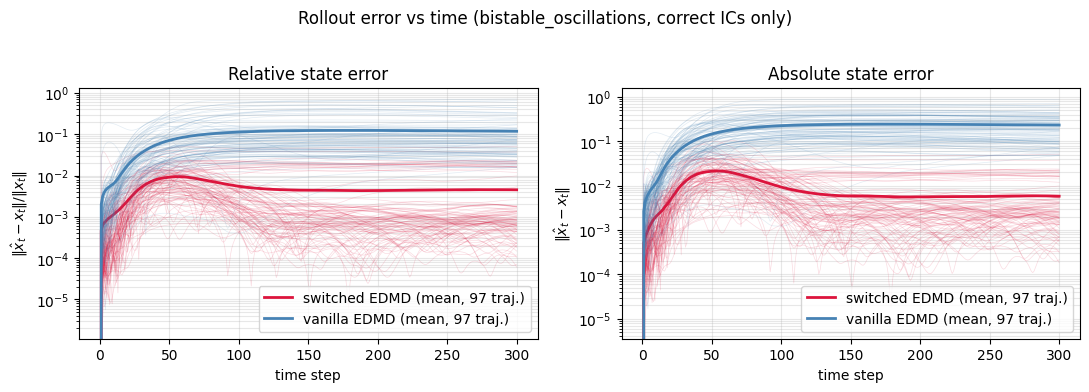

In [11]:
ev = bmlm.run_classification_gated_evaluation(mlm_cfg, models=fit["models"], partition=partition,
                                              Phi_edmd=fit["Phi_edmd"], vanilla_model=fit["vanilla_model"],
                                              Phi_vanilla=fit["Phi_vanilla"])
c = ev["error_curves"]
np.savez(data_path(SYSTEM, "rollout_errors"), **c, rel_rmse_times=ev["rel_rmse_times"], rel_rmse_values=ev["rel_rmse_values"],
         vanilla_rel_rmse_values=ev["vanilla_rel_rmse_values"], partition_accuracy=ev["partition_accuracy"], system_name=NAME)
_ = bmlm.plot_rollout_errors(c["rel_regional"], c["abs_regional"], rel_vanilla=c.get("rel_vanilla"),
                             abs_vanilla=c.get("abs_vanilla"), system_name=NAME, show=True,
                             save_path=fig(SYSTEM, "rollout_errors"))
